#Alexnet
Alexnet was introduced in 2012 and won the ImageNet Challenge. It brought about many new concepts and breakthroughs and are used even in today's models. <br>
One of the most noticeable improvements was its network architecture. AlexNet was deeper and larger than its predecessor, Lenet. It consisted of eight layers, including five convolutional layers and three fully connected layers.<br>
It was also the first model to ever use RELU as its activation function. RELU helped to solve the vanishing graident problem that exist in sigmoid and tanh.Additionally, AlexNet also utilized more techniques such as dropout and regularization during training to prevent overfitting.

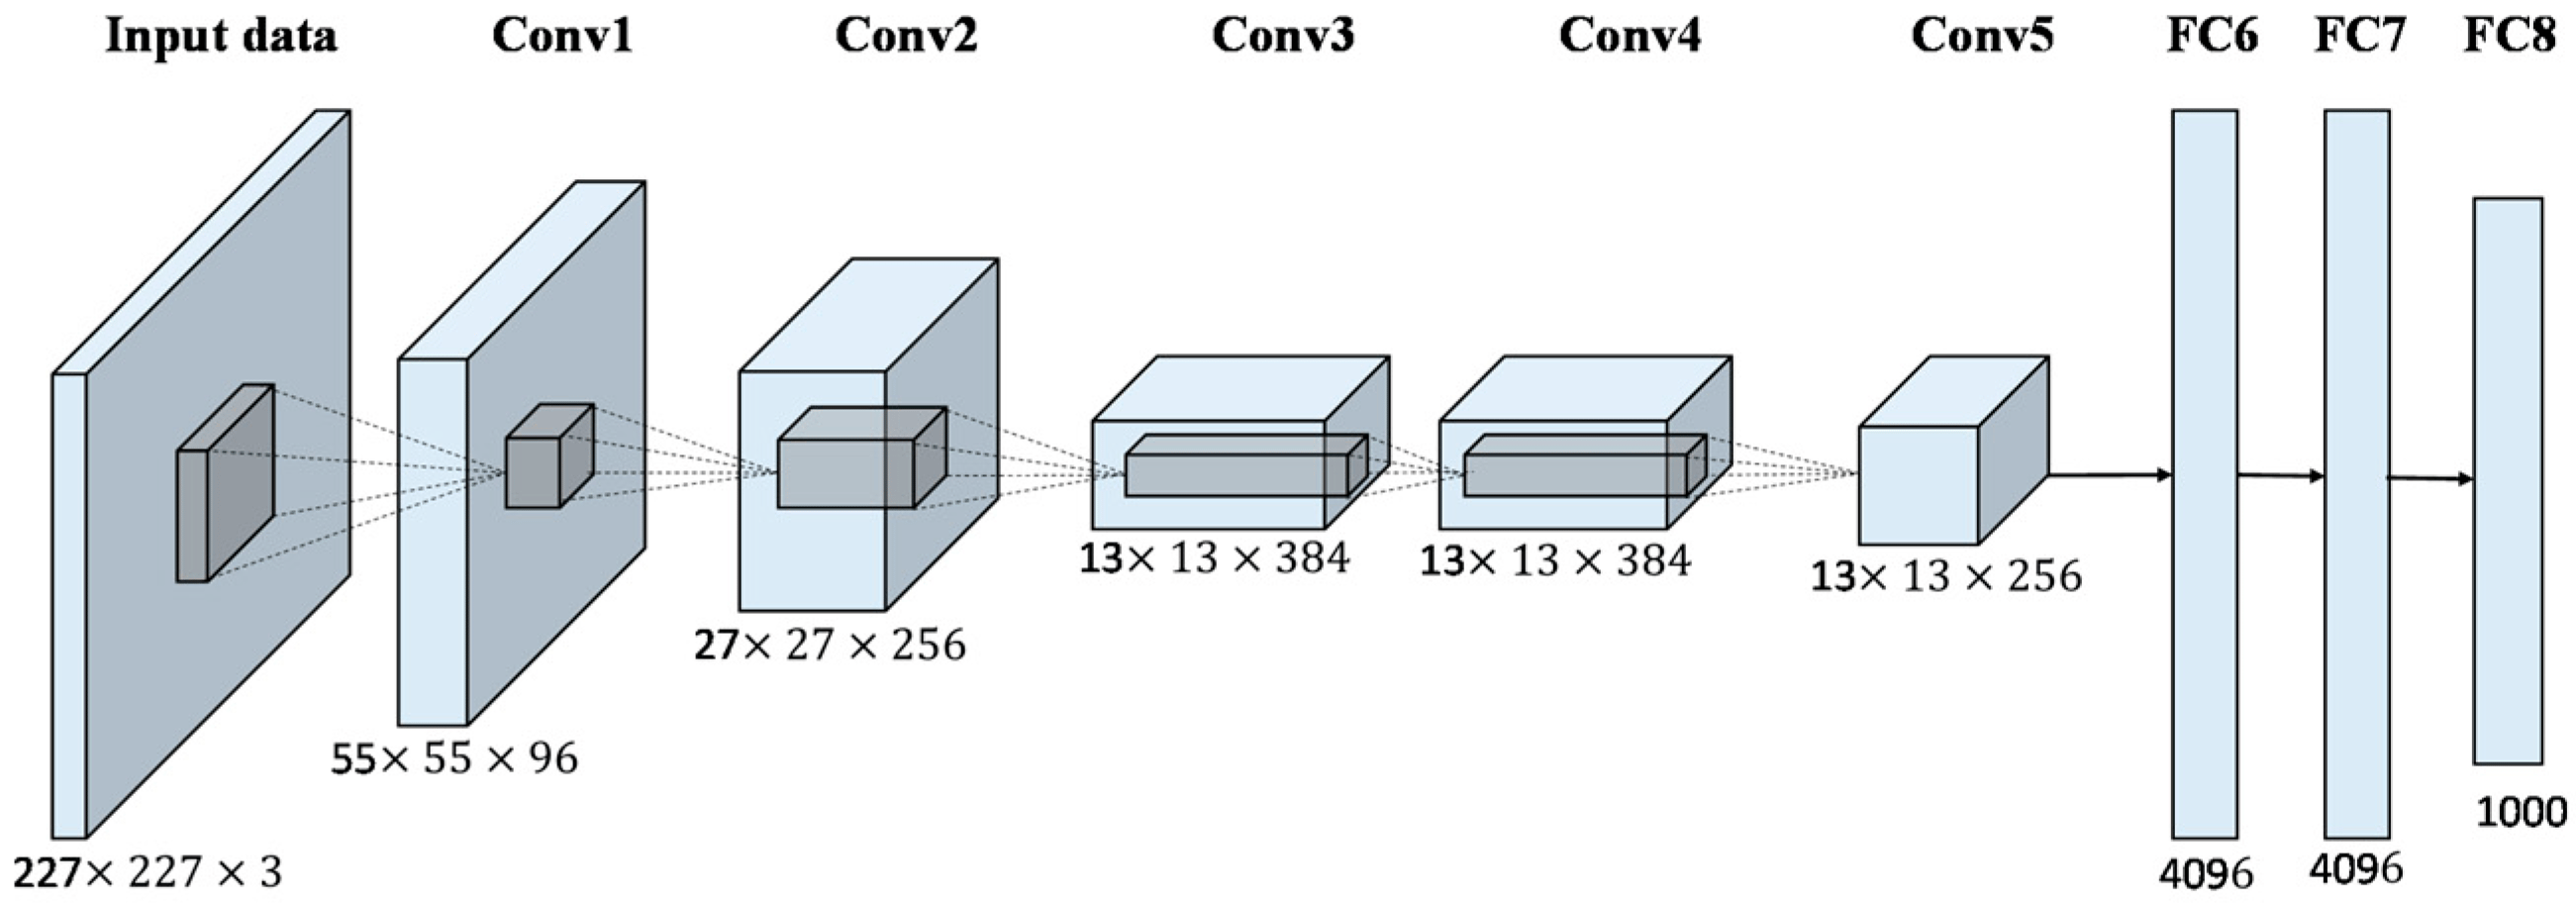

In [1]:
from tensorflow.keras.datasets import cifar10
import os
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelBinarizer
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import utils
from tensorflow.keras.models import Sequential, save_model, load_model
from tensorflow.keras.layers import Dense, Flatten, Conv2D, Dropout, MaxPooling2D, GlobalAveragePooling2D, Activation, BatchNormalization
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, LearningRateScheduler
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras import regularizers
from sklearn.model_selection import cross_val_score
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from keras.utils import plot_model
from PIL import Image

In [33]:
#Loading in cifar10 file and splitting them into training set and test set
(trainX, trainY), (testX, testY) = cifar10.load_data()

In [34]:
#Convert values to float
trainX = trainX.astype("float")
testX = testX.astype("float")

#Pixel normalisation which divide each instance by 255 so that all the image pixels are between 0 and 1
trainX = trainX / 255.0
testX = testX / 255.0

lb = LabelBinarizer() #The current values in trainY and testY are from 0-9, each corresponding to its respective classes. 
trainY = lb.fit_transform(trainY) #Label binarizer basically one hot encode the array, converting all to 0 except the correct index which will be a 1.
testY = lb.transform(testY)

In [35]:
def alexnet(dropout, learning_rate):
    
    model = Sequential() #Initialising Sequential model

    #All layers uses RELU activation function and same padding to preserve the input and output image size. 
    #The kernel size is 3x3 and pool size is 2x2 for all layers. This is different from the original Alexnet as the images in CIFAR10 are much smaller.
    #L2 regularizer is used to prevent the model from overfitting.
    #Dropout is set as a variable for hyperparameter tuning later on. 
    
    #First convolutional layer
    model.add(Conv2D(filters=128, kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(1e-4), input_shape=(32,32,3)))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Dropout(dropout))
    
    #Second convolutional layer
    model.add(Conv2D(filters=256, kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(1e-4)))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Dropout(dropout))
    
    #Third, fourth, fifth convolution layer
    model.add(Conv2D(filters=512, kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(1e-4)))
    model.add(Conv2D(filters=512, kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(1e-4)))
    model.add(Conv2D(filters=256, kernel_size=(3,3), activation='relu', padding='same', kernel_regularizer=regularizers.l2(1e-4)))
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Dropout(dropout))

    #Fully connected layers
    model.add(Flatten())
    
    model.add(Dense(512, activation='relu'))
    model.add(Dropout(dropout))
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(dropout))
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(dropout))
    
    #Classification layer
    model.add(Dense(10, activation='softmax'))

    #Model compiler. Categorical crossentropy is used as the loss function. Adam is used the optimizer
    #Model evaluation will be based on accuracy
    model.compile(loss='categorical_crossentropy',
             optimizer=Adam(learning_rate=learning_rate),
             metrics=['accuracy'])
    
    return model

In [36]:
model = alexnet(0.3, 0.0003) #Call the model

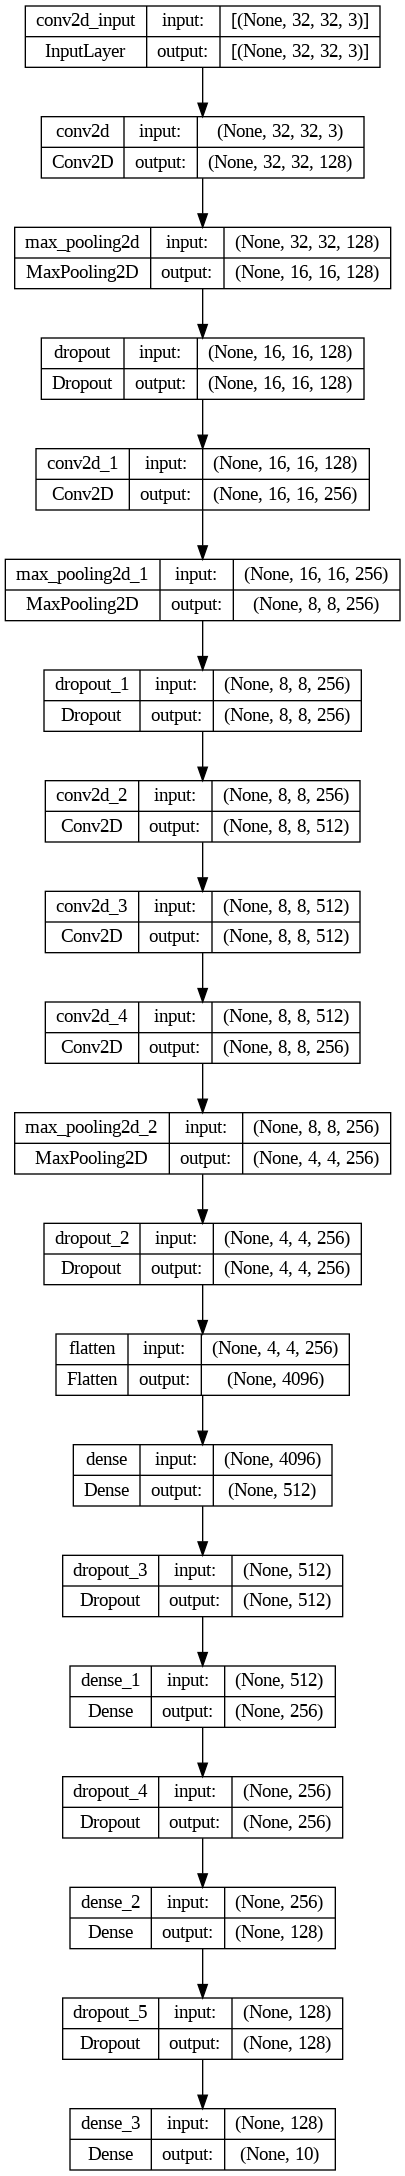

In [6]:
plot_model(model, to_file = "alexnet_cifar10_architecture.png", show_shapes = True)

In [37]:
#Fit and run model for 10 epochs
history = model.fit(trainX, trainY, 
                    batch_size = 32,
                    steps_per_epoch = len(trainX) // 32, 
                    epochs = 10, 
                    validation_data= (testX, testY),
                    verbose=1)

Epoch 1/10
1562/1562 [==============================] - 34s 19ms/step - loss: 1.8079 - accuracy: 0.3351 - val_loss: 1.3868 - val_accuracy: 0.4851
Epoch 2/10
1562/1562 [==============================] - 30s 19ms/step - loss: 1.3379 - accuracy: 0.5285 - val_loss: 1.1618 - val_accuracy: 0.5966
Epoch 3/10
1562/1562 [==============================] - 30s 19ms/step - loss: 1.1388 - accuracy: 0.6167 - val_loss: 1.0365 - val_accuracy: 0.6525
Epoch 4/10
1562/1562 [==============================] - 30s 19ms/step - loss: 1.0122 - accuracy: 0.6685 - val_loss: 0.9368 - val_accuracy: 0.6864
Epoch 5/10
1562/1562 [==============================] - 30s 19ms/step - loss: 0.9133 - accuracy: 0.7097 - val_loss: 0.8843 - val_accuracy: 0.7188
Epoch 6/10
1562/1562 [==============================] - 30s 19ms/step - loss: 0.8382 - accuracy: 0.7376 - val_loss: 0.8143 - val_accuracy: 0.7517
Epoch 7/10
1562/1562 [==============================] - 29s 19ms/step - loss: 0.7789 - accuracy: 0.7643 - val_loss: 0.7994 -

In [38]:
score=model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 2s 6ms/step - loss: 0.7396 - accuracy: 0.7892
Test Score= 0.7396286725997925
Test Accuracy= 0.7892000079154968


In [8]:
def fit_with(dropout, batch_size, learning_rate):
    model = alexnet(dropout, learning_rate)

    # Train the model with the train dataset. 
    model.fit(trainX, trainY, 
                    batch_size = round(batch_size),
                    steps_per_epoch = round(len(trainX) // batch_size), 
                    epochs = 10, 
                    validation_data= (testX, testY),
                    verbose=0)

    # Evaluate the model with the eval dataset.
    score=model.evaluate(testX, testY)
    print('Test loss:', score[0])
    print('Test accuracy:', score[1])

    # Return the accuracy.
    return score[1]

In [11]:
from bayes_opt import BayesianOptimization
bounds ={
    'batch_size':(32, 64),
    'dropout':(0.1, 0.5),
    'learning_rate':(0.0003, 0.0005)
}
optimizer = BayesianOptimization(fit_with, bounds, random_state = 1, verbose = 2)
optimizer.maximize(init_points=6, n_iter=3)

for i, res in enumerate(optimizer.res):
    print("Iteration {}: \n\t{}".format(i, res))

|   iter    |  target   | batch_... |  dropout  | learni... |
-------------------------------------------------------------
313/313 [==============================] - 2s 7ms/step - loss: 0.7725 - accuracy: 0.7714
Test loss: 0.7724698781967163
Test accuracy: 0.771399974822998
| 1         | 0.7714    | 45.34     | 0.3881    | 0.0003    |


313/313 [==============================] - 2s 7ms/step - loss: 0.7386 - accuracy: 0.8018
Test loss: 0.7386155128479004
Test accuracy: 0.801800012588501
| 2         | 0.8018    | 41.67     | 0.1587    | 0.0003185 |


313/313 [==============================] - 2s 6ms/step - loss: 0.6944 - accuracy: 0.8006
Test loss: 0.694360613822937
Test accuracy: 0.800599992275238
| 3         | 0.8006    | 37.96     | 0.2382    | 0.0003794 |
313/313 [==============================] - 2s 6ms/step - loss: 0.7013 - accuracy: 0.7942
Test loss: 0.7013051509857178
Test accuracy: 0.7942000031471252
| 4         | 0.7942    | 49.24     | 0.2677    | 0.000437  |


313/313 [==============================] - 2s 6ms/step - loss: 0.7690 - accuracy: 0.7723
Test loss: 0.7689996361732483
Test accuracy: 0.7723000049591064
| 5         | 0.7723    | 38.54     | 0.4512    | 0.0003055 |
313/313 [==============================] - 2s 6ms/step - loss: 0.7337 - accuracy: 0.7921
Test loss: 0.7336525321006775
Test accuracy: 0.7921000123023987
| 6         | 0.7921    | 53.45     | 0.2669    | 0.0004117 |
313/313 [==============================] - 2s 6ms/step - loss: 0.8219 - accuracy: 0.7404
Test loss: 0.8218827843666077
Test accuracy: 0.7404000163078308
| 7         | 0.7404    | 44.03     | 0.416     | 0.0004549 |


313/313 [==============================] - 2s 6ms/step - loss: 0.7488 - accuracy: 0.7919
Test loss: 0.7488061785697937
Test accuracy: 0.7918999791145325
| 8         | 0.7919    | 41.66     | 0.1251    | 0.0004411 |


313/313 [==============================] - 2s 6ms/step - loss: 0.7108 - accuracy: 0.7921
Test loss: 0.7107963562011719
Test accuracy: 0.7921000123023987
| 9         | 0.7921    | 41.73     | 0.2606    | 0.0003    |
Iteration 0: 
	{'target': 0.771399974822998, 'params': {'batch_size': 45.34470415048237, 'dropout': 0.38812979737686326, 'learning_rate': 0.00030002287496346897}}
Iteration 1: 
	{'target': 0.801800012588501, 'params': {'batch_size': 41.67464232421887, 'dropout': 0.15870235632684523, 'learning_rate': 0.00031846771895375955}}
Iteration 2: 
	{'target': 0.800599992275238, 'params': {'batch_size': 37.960326764085465, 'dropout': 0.2382242908172191, 'learning_rate': 0.000379353494846134}}
Iteration 3: 
	{'target': 0.7942000031471252, 'params': {'batch_size': 49.24213548810742, 'dropout': 0.26767780576131794, 'learning_rate': 0.0004370439000793519}}
Iteration 4: 
	{'target': 0.7723000049591064, 'params': {'batch_size': 38.54247199140856, 'dropout': 0.4512469745563782, 'learning_rate

In [17]:
print(optimizer.max)

{'target': 0.801800012588501, 'params': {'batch_size': 41.67464232421887, 'dropout': 0.15870235632684523, 'learning_rate': 0.00031846771895375955}}


In [13]:
checkpoint_path = "training_2/cp-{epoch:04d}.ckpt"
checkpoint_dir = os.path.dirname(checkpoint_path)

In [14]:
checkpoint = ModelCheckpoint(filepath=checkpoint_path,
                             monitor='accuracy',
                             verbose=1)

#Stop model from continuing when the accuracy does not increase after 10 continuous epochs. 
#The model will then restore model weights from the epoch with the best
early_stopping = EarlyStopping(monitor='val_accuracy', mode='max', verbose=0, patience=10, restore_best_weights = True)

In [18]:
#Data augmentation, which generates variations of images from the dataset. This is a way to provide more training samples for the model to learn
aug = ImageDataGenerator(rotation_range=10, width_shift_range=0.1,height_shift_range=0.1, horizontal_flip=True,fill_mode="nearest")

In [15]:
import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)

In [20]:
dropout = 0.2
learning_rate = 0.0003
batch_size = 32

optimized_model = alexnet(dropout, learning_rate)

AlexNet_history = optimized_model.fit(aug.flow(trainX, trainY, batch_size = batch_size),
                    steps_per_epoch = len(trainX) // batch_size, 
                    epochs = 75, 
                    validation_data= (testX, testY),
                    verbose=1,
                    callbacks=[checkpoint, early_stopping])

Epoch 1/75
1562/1562 [==============================] - ETA: 0s - loss: 1.8129 - accuracy: 0.3313
Epoch 1: saving model to training_2/cp-0001.ckpt
1562/1562 [==============================] - 51s 30ms/step - loss: 1.8129 - accuracy: 0.3313 - val_loss: 1.4659 - val_accuracy: 0.4709
Epoch 2/75
1562/1562 [==============================] - ETA: 0s - loss: 1.3699 - accuracy: 0.5174
Epoch 2: saving model to training_2/cp-0002.ckpt
1562/1562 [==============================] - 46s 29ms/step - loss: 1.3699 - accuracy: 0.5174 - val_loss: 1.2238 - val_accuracy: 0.5658
Epoch 3/75
1562/1562 [==============================] - ETA: 0s - loss: 1.2057 - accuracy: 0.5876
Epoch 3: saving model to training_2/cp-0003.ckpt
1562/1562 [==============================] - 45s 29ms/step - loss: 1.2057 - accuracy: 0.5876 - val_loss: 0.9760 - val_accuracy: 0.6695
Epoch 4/75
1562/1562 [==============================] - ETA: 0s - loss: 1.0889 - accuracy: 0.6371
Epoch 4: saving model to training_2/cp-0004.ckpt
1562/15

In [21]:
optimized_model.save('alexnet.keras')

In [22]:
score=optimized_model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 2s 6ms/step - loss: 0.5982 - accuracy: 0.8710
Test Score= 0.5982432961463928
Test Accuracy= 0.8709999918937683


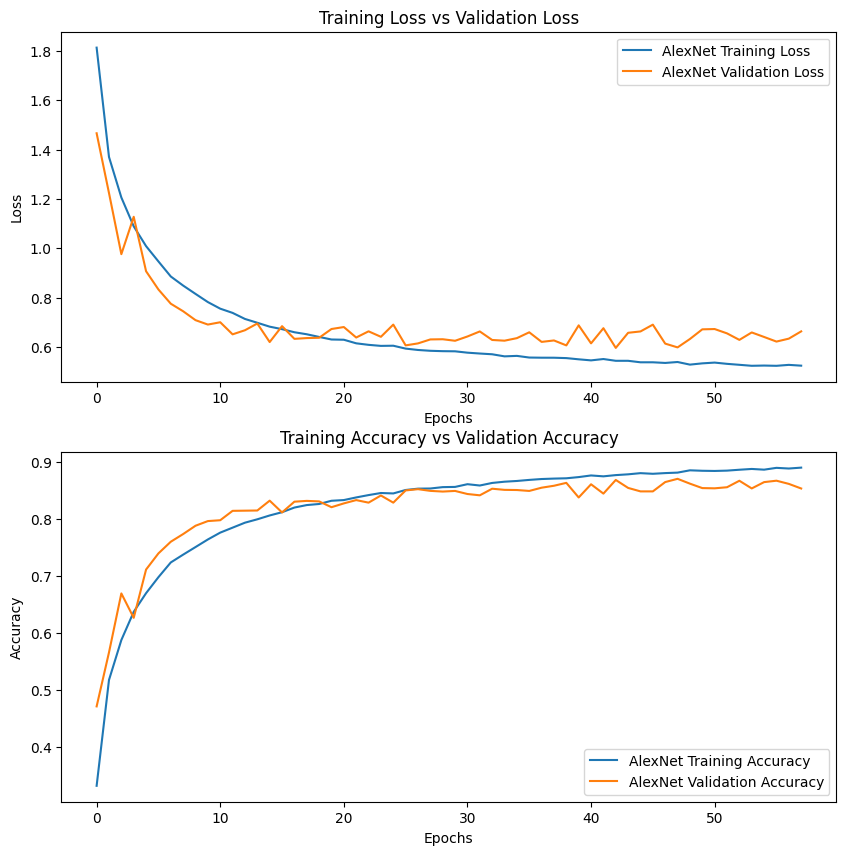

In [23]:
fig, axs = plt.subplots(2, 1, figsize=(10,10))

axs[0].plot(AlexNet_history.history['loss'])
axs[0].plot(AlexNet_history.history['val_loss'])

axs[0].title.set_text('Training Loss vs Validation Loss')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend(['AlexNet Training Loss', 'AlexNet Validation Loss'])

axs[1].plot(AlexNet_history.history['accuracy'])
axs[1].plot(AlexNet_history.history['val_accuracy'])
axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend(['AlexNet Training Accuracy', 'AlexNet Validation Accuracy'])

In [24]:
pred = optimized_model.predict(testX)

313/313 [==============================] - 1s 4ms/step


In [25]:
from sklearn.metrics import classification_report
y_pred = np.argmax(pred, axis=1)
y_true = np.argmax(testY, axis=1)
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1000
           1       0.93      0.95      0.94      1000
           2       0.84      0.82      0.83      1000
           3       0.82      0.67      0.74      1000
           4       0.86      0.87      0.86      1000
           5       0.79      0.82      0.81      1000
           6       0.90      0.91      0.91      1000
           7       0.88      0.93      0.91      1000
           8       0.95      0.90      0.92      1000
           9       0.89      0.93      0.91      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



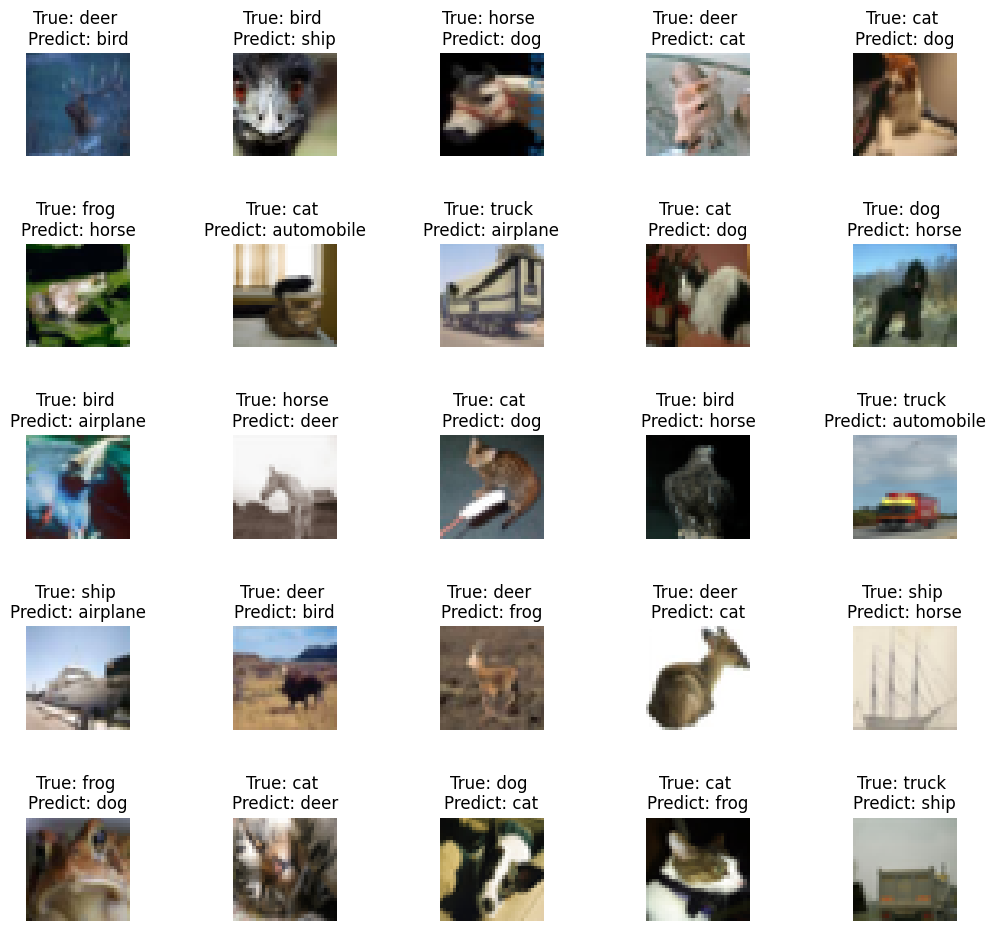

In [30]:
fig, axes = plt.subplots(5, 5, figsize=(12,12))
axes = axes.ravel()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
testX = testX * 255

miss_pred = np.where(y_pred != y_true)[0]
for i in np.arange(25): 
    axes[i].imshow(testX[miss_pred[i]].astype('uint8'))
    axes[i].set_title('True: %s \nPredict: %s' % (class_names[y_true[miss_pred[i]]], class_names[y_pred[miss_pred[i]]]))
    axes[i].axis('off')
    plt.subplots_adjust(wspace=1)

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import seaborn as sns
confusion_matrix = tf.math.confusion_matrix(labels=y_true, predictions=y_pred)
confusion_matrix = confusion_matrix.numpy()

Text(0.5, 1.0, 'Confusion Matrix')

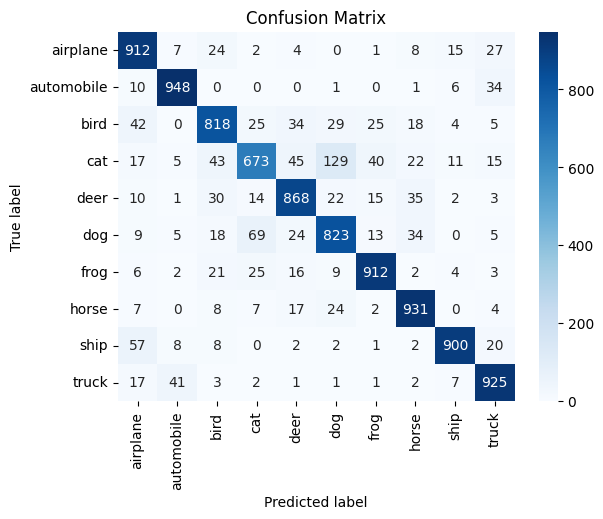

In [32]:
sns.heatmap(confusion_matrix, annot=True, fmt="g", xticklabels = class_names, yticklabels = class_names, cmap=plt.cm.Blues)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')